In [2]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import pandas as pd

TypeError: a() missing 2 required positional arguments: 'scherrate' and 'scherviskositaet'

### dynamische Messung 2

In [5]:
gamma_dyn2_probe1 = np.array()
G1_dyn2_probe1 = np.array([])
G2_dyn2_probe1 = np.array([])

gamma_dyn2_probe2 = np.array()
G1_dyn2_probe2 = np.array([])
G2_dyn2_probe2 = np.array([])


### Fließkurve

In [7]:
visk_1 = np.array([])
schubspannung_1 = np.array([])
visk_2 = np.array([])
schubspannung_2 = np.array([])

### Rechnung

Cross
 Nullscher: 18.72491035610338
 kappa 0.19019841800991738
Carr
 Nullscher: 17.281807342033137
 kappa 10.795235561379474


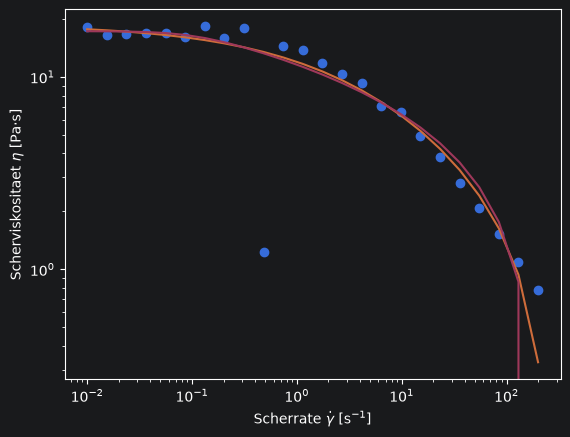

In [35]:
a(testdaten_raw.Scherrate_1_s.array, testdaten_raw.Viskositaet_Pa_s.array)

In [12]:
###Helper

def plot_loglog(x, y, label_x, label_y, ax=None,label=""):
    if ax is None:
        fig, ax = plt.subplots()
    ax.plot(x, y, "o",label=label)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(label_x)
    ax.set_ylabel(label_y)
    if label!="":
        ax.legend()
    return ax



### a)

In [25]:
def a(scherrate, scherviskositaet):
    fig, ax = plt.subplots()
    ax.plot(scherrate, scherviskositaet, "o")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Scherrate $\dot \gamma$ [s$^{-1}$]")
    ax.set_ylabel(r"Scherviskositaet $\eta$ [Pa$\cdot$s]")#
    nullscher_cross, kappa_cross = fit_cross(scherrate, scherviskositaet, ax)
    nullscher_carr, kappa_carr = fit_carreau(scherrate, scherviskositaet, ax)
    ax.legend()
    print(
        f"Cross\n Nullscher: {nullscher_cross}\n kappa {kappa_cross}\nCarr\n Nullscher: {nullscher_carr}\n kappa {kappa_carr}")


def cross(scherrate, n, kappa, nullscherviskositaet, hochscherviskositaet):
    return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (1 + (kappa * scherrate) ** n)


def carreau(scherrate, n, kappa, nullscherviskositaet, hochscherviskositaet):
    return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (
            (1 + (kappa * scherrate) ** 2) ** (n / 2))


def fit_cross(scherrate, scherviskositaet, ax):
    opt, cov = curve_fit(cross, scherrate, scherviskositaet)
    ax.plot(scherrate, cross(scherrate, *opt), label="CrossFit")
    return opt[-2,], opt[1]


def fit_carreau(scherrate, scherviskositaet, ax):
    opt, cov = curve_fit(carreau, scherrate, scherviskositaet)
    ax.plot(scherrate, carreau(scherrate, *opt), label="Carreau Fit")
    return opt[-2,], opt[1]



In [45]:
testdaten_b = pd.read_excel('Rheologie_780790_Bereinigte_Daten.xlsx', sheet_name="Bereinigt_Amplitude")
b(testdaten_b.Deformation_gamma.array, testdaten_b.Schubspannung_Pa.array, testdaten_b.Speichermodul_Gprime_Pa.array,
  testdaten_b.Verlustmodul_Gdoppelprime_Pa.array)

TypeError: b() missing 4 required positional arguments: 'g11', 'g21', 'g17', and 'g27'

### b)

In [34]:
def b(gamma1, gamma7, schubspannung1, schubspannung7, g11, g21, g17, g27):
    ax_1_gamma = plot_loglog(gamma1, g21, r"Deformation $\gamma$", r"Verlustmodul $G^{\prime\prime}$",label="Verlustmodul bei 1 Hz")
    plot_loglog(gamma1, g11, r"Deformation $\gamma$", r"Speichermodul $G^\prime$",ax=ax_1_gamma,label="Speichermodul bei 1 Hz")
    ax_7_gamma=plot_loglog(gamma7, g17, r"Deformation $\gamma$", r"Speichermodul $G^\prime$",label="Speichermodul bei 7 Hz")
    plot_loglog(gamma7, g27, r"Deformation $\gamma$", r"Verlustmodul $G^{\prime\prime}$",ax=ax_7_gamma,label="Verlustmodul bei 7 Hz")

    ax_1_omega = plot_loglog(schubspannung1, g11, r"Schuspannung $\sigma", r"Speichermodul $G^\prime$",label="Speichermodul bei 1 Hz")
    plot_loglog(schubspannung1, g21, r"Schubspannung $\sigma", r"Verlustmodul $G^{\prime\prime}$",ax=ax_1_omega,label="Verlustmodul bei 1 Hz")
    ax_7_omega=plot_loglog(schubspannung7, g17, r"Schubspannung $\sigma", r"Speichermodul $G^\prime$",label="Speichermodul bei 7 Hz")
    plot_loglog(schubspannung7, g27, r"Schubspannung $\sigma", r"Verlustmodul $G^{\prime\prime}$",ax=ax_7_omega,label="Verlustmodul bei 7 Hz")

    return ax_1_gamma, ax_1_omega,  ax_7_gamma, ax_7_omega,






### c)

In [66]:
from scipy.constants import pi


def c(frequenz, g1, g2):
    winkelfrequnez = 2 * pi * frequenz
    ax = plot_loglog(winkelfrequnez, g1, r"Winkelfrequenz $\omega$ [rad$$\cdot$s$^{-1}$",
                        r"Speichermodul $G^\prime$",label="Speichermodul")
    plot_loglog(winkelfrequnez, g2, r"Winkelfrequenz $\omega$ [rad$$\cdot$s$^{-1}$",
                        r"Verlustmodul $G^{\prime\prime}$",ax=ax,label="Verlustmodul")
    tau_g1, g0_g1 = fit_maxwell_g1(winkelfrequnez[0:11], g1[0:11], ax)
    tau_g2, g0_g2 = fit_maxwell_g2(winkelfrequnez[0:11], g2[0:11], ax)
    ax.legend()
    print(f"""G1
    Relaxationszeit {tau_g1}
    Plateaumodul {g0_g1}
G2
    Relaxationszeit {tau_g2}
    Plateaumodul {g0_g2}""")


def fit_maxwell_g1(winkelfrequenz, g1, ax):
    opt, cov = curve_fit(maxwell_g1, winkelfrequenz, g1,p0=[0.01,20],maxfev=10000)
    ax.plot(winkelfrequenz, maxwell_g1(winkelfrequenz, *opt),label="Maxwell Speichermodul")
    return opt


def fit_maxwell_g2(winkelfrequenz, g2, ax):
    opt, cov = curve_fit(maxwell_g2, winkelfrequenz, g2,p0=[0.01,20],maxfev=10000)
    ax.plot(winkelfrequenz, maxwell_g2(winkelfrequenz, *opt),label="Maxwell Verlustmodul")
    return opt


def maxwell_g1(omega, tau, g0):
    return g0 * (omega * tau) ** 2 / (1 + (omega * tau) ** 2)


def maxwell_g2(omega, tau, g0):
    return g0 * (omega * tau) / (1 + (omega * tau) ** 2)

### d)

In [18]:
def d(g1, g2, g0):
    fig, ax = plt.subplots()
    ax.scatter(g1, g2)
    ax.set_xlabel(r"Speichermodul G$^\prime$")
    ax.set_ylabel(r"Verlustmodul G$^{\prime\prime}$")

    x = np.linspace(g1[0], g1[-1], 100)
    calc_g2 = np.sqrt(x * (g0 - x))

    ax.plot(x, calc_g2)


### f)

Cross
 Nullscher: 3.4512168470712226
 kappa 0.038574992128838394
Carr
 Nullscher: 3.4394926788903692
 kappa 0.05752389808748947


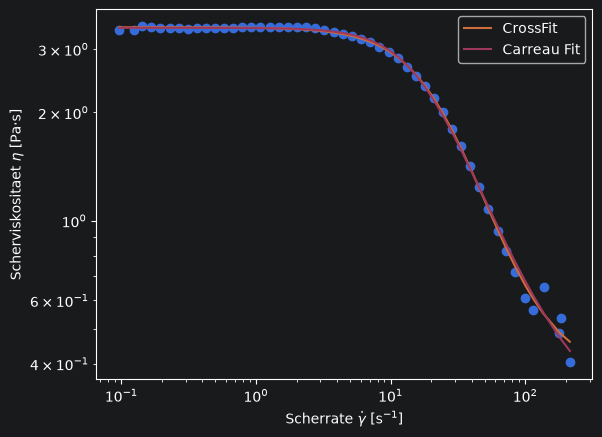

In [26]:
viskositaet_niedrigviskos = np.loadtxt("Niedrigviskos-250-viskositaet.txt",encoding="latin-1",skiprows=1,unpack=True)

scherviskos =viskositaet_niedrigviskos[2]
scherrate = viskositaet_niedrigviskos[0]

a(scherrate,scherviskos)

array([38.46, 38.02, 33.93, 33.81, 31.96, 30.02, 31.12, 28.38, 29.57,
       30.48, 30.22, 32.13, 33.4 , 31.4 , 34.06, 30.04, 30.37, 28.49,
       28.09, 26.76, 23.94, 26.65, 22.27, 23.62, 22.68, 22.32, 24.28,
       23.53, 23.39, 25.36])

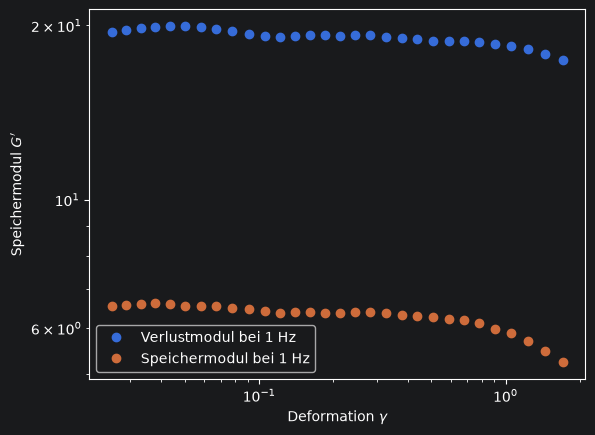

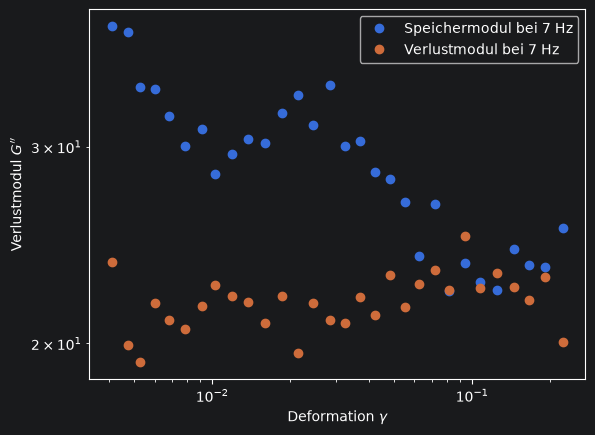

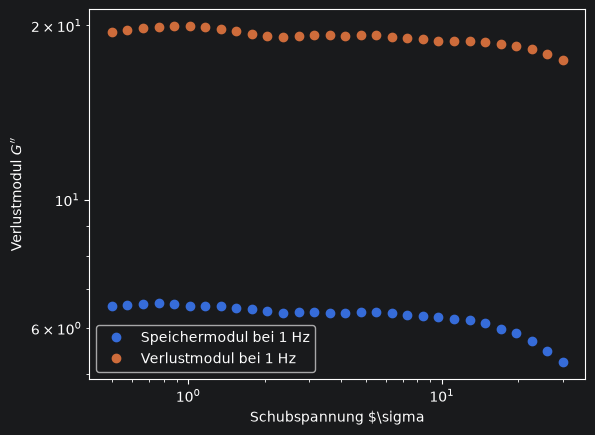

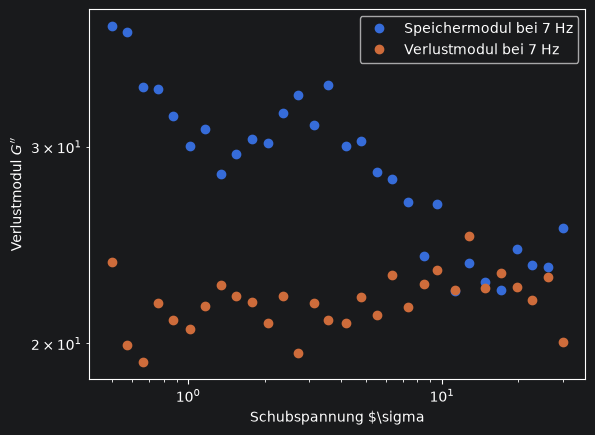

In [38]:
n_deform_1, n_schubspannung_1,n_g1_1, n_g2_1 = np.loadtxt("Niedrigviskos-250-1hz.txt",encoding="latin1",skiprows=1,usecols=[9,8,4,5],unpack=True)
n_deform_7, n_schubspannung_7,n_g1_7, n_g2_7 = np.loadtxt("Niedrigviskos-7hz-250.txt",encoding="latin1",skiprows=1,usecols=[9,8,4,5],unpack=True)

# Zeit s	Temperatur °C	Frequenz Hz	Komp. Schubmodul Pa	Elastischer Modul Pa	Viskoser Modul Pa	Komplexe Viskosität Pas	Phasenwinkel °	Schubspannung Pa	Deformation  	Summierte Zeit s	Eta'' Pas	Dynamische Viskosität Pas	Hinweis

b(n_deform_1,n_deform_7,n_schubspannung_1,n_schubspannung_7,n_g1_1,n_g2_1,n_g1_7,n_g2_7)

n_g1_7

G1
    Relaxationszeit 0.0687815419859557
    Plateaumodul 41.44841082018439
G2
    Relaxationszeit 0.054945684370923065
    Plateaumodul 59.61687810937313


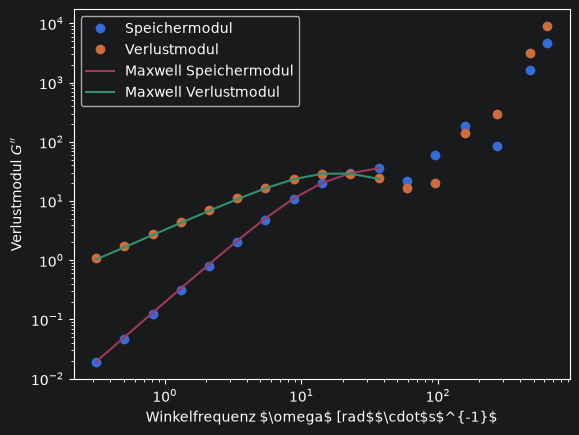

In [68]:
n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt",encoding="latin-1",skiprows=1,unpack=True,usecols=range(0,13))
frequenz = n_oszilla[2]
g1 = n_oszilla[4]
g2 = n_oszilla[5]
c(frequenz, g1, g2)

array([1.888e-02, 4.664e-02, 1.237e-01, 3.090e-01, 7.860e-01, 2.006e+00,
       4.845e+00, 1.074e+01, 2.023e+01, 2.980e+01, 3.560e+01])

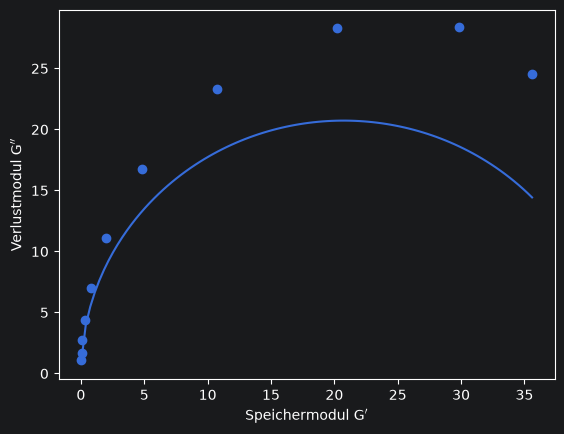

In [93]:
n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt",encoding="latin-1",skiprows=1,unpack=True,usecols=range(0,13))
g1 = n_oszilla[4][0:11]
g2 = n_oszilla[5][0:11]

d(g1,g2,41.448)
g1

<Axes: xlabel='Kreisfreq', ylabel='Kompvisk'>

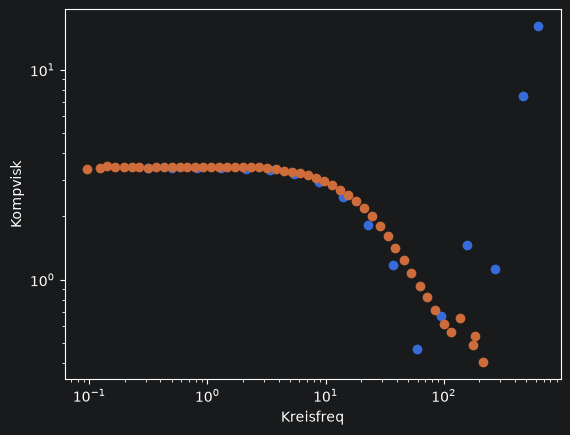

In [83]:
n_oszilla = np.loadtxt("Niedrigviskos-250-oszillation.txt",encoding="latin-1",skiprows=1,unpack=True,usecols=range(0,13))
cvisk = n_oszilla[6]
freq = n_oszilla[2]

viskositaet_niedrigviskos = np.loadtxt("Niedrigviskos-250-viskositaet.txt",encoding="latin-1",skiprows=1,unpack=True)

scherviskos =viskositaet_niedrigviskos[2]
scherrate = viskositaet_niedrigviskos[0]

ax =plot_loglog(freq*2*pi,cvisk,"Kreisfreq","Kompvisk")
plot_loglog(scherrate,scherviskos,"Kreisfreq","Kompvisk",ax=ax)


Cross
 Nullscher: 27.27240328445722
 kappa 0.258691395645653
Carr
 Nullscher: 27.078716986930427
 kappa 0.38559811436292063
G1
    Relaxationszeit 0.584038913405309
    Plateaumodul 50.74507581588438
G2
    Relaxationszeit 0.4581252536935435
    Plateaumodul 60.30388086794458


/tmp/ipykernel_27000/3841270930.py:16: RuntimeWarning: invalid value encountered in power
  return hochscherviskositaet + (nullscherviskositaet - hochscherviskositaet) / (1 + (kappa * scherrate) ** n)


<Axes: xlabel='Kreisfreq', ylabel='Kompvisk'>

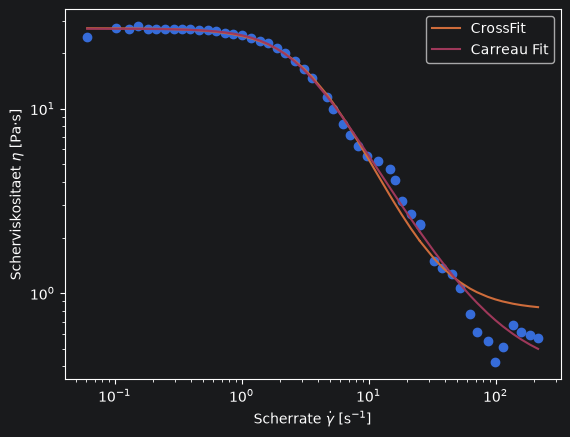

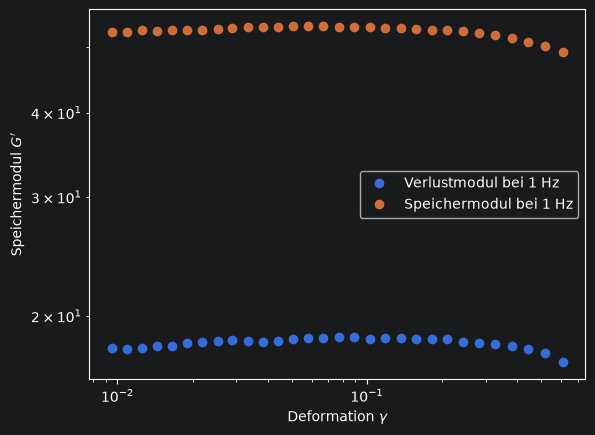

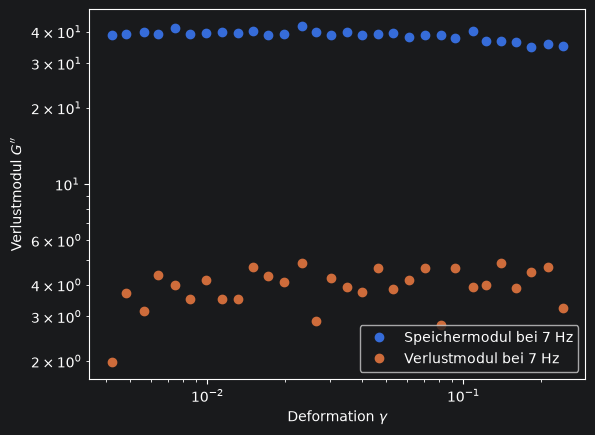

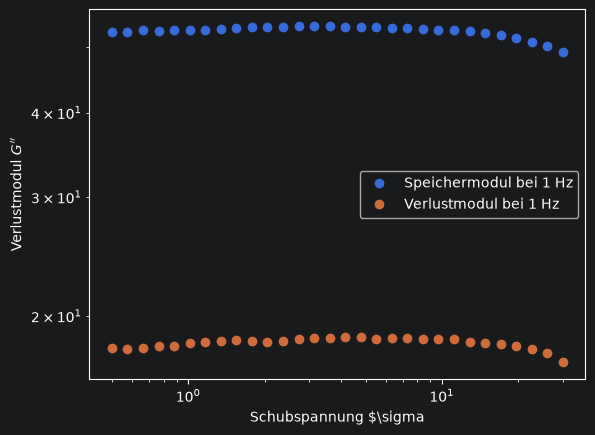

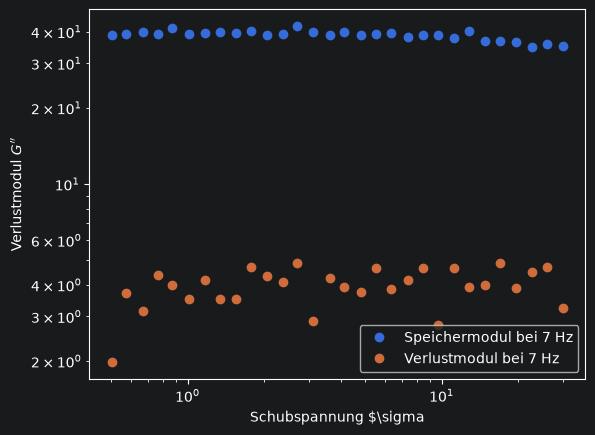

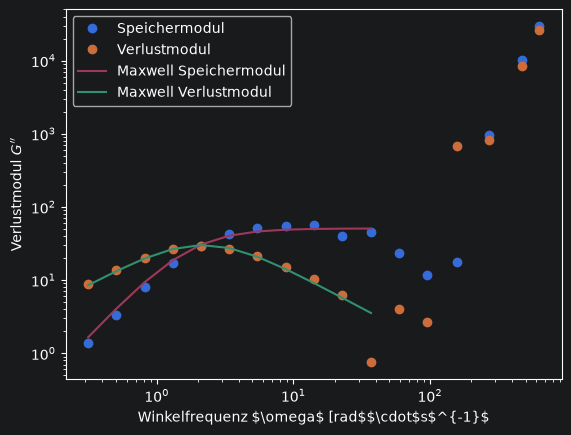

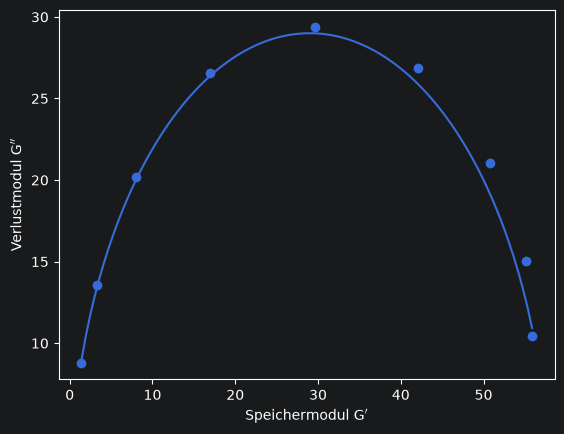

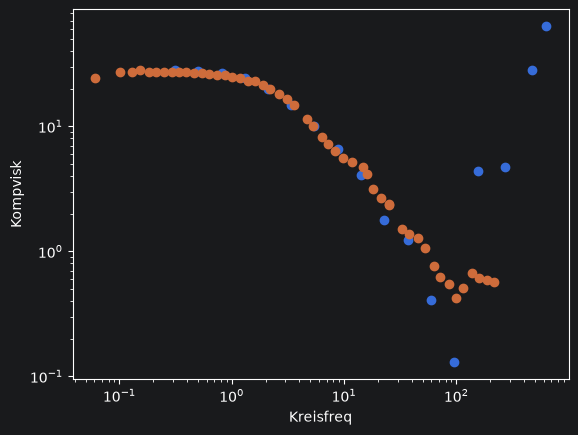

In [91]:
hochvisk_viskos = np.loadtxt("Hochviskos-viskositaet.txt",encoding="latin-1",skiprows=1,unpack=True)

scherviskos =hochvisk_viskos[2]
scherrate = hochvisk_viskos[0]

a(scherrate,scherviskos)

h_deform_1, h_schubspannung_1,h_g1_1, h_g2_1 = np.loadtxt("Hochviskos-1hz.txt",encoding="latin1",skiprows=1,usecols=[9,8,4,5],unpack=True)
h_deform_7, h_schubspannung_7,h_g1_7, h_g2_7 = np.loadtxt("Hochviskos-7hz-richtig.txt",encoding="latin1",skiprows=1,usecols=[9,8,4,5],unpack=True)

# Zeit s	Temperatur °C	Frequenz Hz	Komp. Schubmodul Pa	Elastischer Modul Pa	Viskoser Modul Pa	Komplexe Viskosität Pas	Phasenwinkel °	Schubspannung Pa	Deformation  	Summierte Zeit s	Eta'' Pas	Dynamische Viskosität Pas	Hinweis

b(h_deform_1,h_deform_7,h_schubspannung_1,h_schubspannung_7,h_g1_1,h_g2_1,h_g1_7,h_g2_7)


h_oszilla = np.loadtxt("Hochviskos-oszillation.txt",encoding="latin-1",skiprows=1,unpack=True,usecols=range(0,13))
frequenz = h_oszilla[2]
g1 = h_oszilla[4]
g2 = h_oszilla[5]
c(frequenz, g1, g2)
g1 = h_oszilla[4][0:9]
g2 = h_oszilla[5][0:9]

d(g1,g2,58)
g1
cvisk = h_oszilla[6]
freq = h_oszilla[2]


scherviskos =hochvisk_viskos[2]
scherrate = hochvisk_viskos[0]

ax =plot_loglog(freq*2*pi,cvisk,"Kreisfreq","Kompvisk")
plot_loglog(scherrate,scherviskos,"Kreisfreq","Kompvisk",ax=ax)
